# Tutorial 2 — MLP classification and backpropagation

We train the requested (10,10) Iris classifier, compare hidden-layer sizes and learning rates, and work through a small numerical backward pass.

**How to run:** select a Python kernel with the repository requirements, then Run All. QUICK mode keeps experiments short. For the larger run set `TUTORIAL_FULL=1` before starting the kernel. A quick run demonstrates the method; it is not a final accuracy benchmark.

In [1]:
# Google Colab: fetch the support files and install missing dependencies.
# Local Jupyter: follow README setup once; this cell makes no changes.
import sys, subprocess
from pathlib import Path
if "google.colab" in sys.modules:
    repo = Path("/content/dl-course-tutorials")
    if not repo.exists():
        subprocess.check_call(["git", "clone", "https://github.com/naveed952/Deep_learning-Tutorials_py.ipynb.git", str(repo)])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-r", str(repo/"requirements.txt")])
    import os
    os.chdir(repo)


## Step 1 — Locate the project and set a reproducible seed
A fixed seed makes comparisons easier to reproduce. Each notebook can run independently.

In [2]:
from pathlib import Path
import sys, os
ROOT = Path.cwd() if (Path.cwd()/"tutorial_support").exists() else Path.cwd().parent
assert (ROOT/"tutorial_support").exists(), "Run from the repository or notebooks folder."
sys.path.insert(0, str(ROOT))
from tutorial_support.common import *
seed()
print("Mode:", "QUICK: small real-data run" if QUICK else "FULL: larger training run")

Mode: QUICK: small real-data run


## Step 2 — Make independent train validation and test splits
Use validation accuracy to choose architecture and learning rate. Keep the test split untouched until selection is finished.

In [3]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report,accuracy_score
import pandas as pd
import matplotlib.pyplot as plt
X,y=load_iris(return_X_y=True)
Xa,Xte,ya,yte=train_test_split(X,y,test_size=.2,stratify=y,random_state=SEED)
Xtr,Xv,ytr,yv=train_test_split(Xa,ya,test_size=.25,stratify=ya,random_state=SEED)
scaler=StandardScaler().fit(Xtr)
Xtr,Xv,Xte=[scaler.transform(a) for a in (Xtr,Xv,Xte)]

## Step 3 — Train the baseline and inspect its structure
A Dense connection contains one weight for each input/output pair and one bias per output. ReLU is the hidden activation; the three-class output uses softmax internally.

Layers: 4 iterations: 575 output: softmax
Weight shapes: [(4, 10), (10, 10), (10, 3)]
Parameters: 193


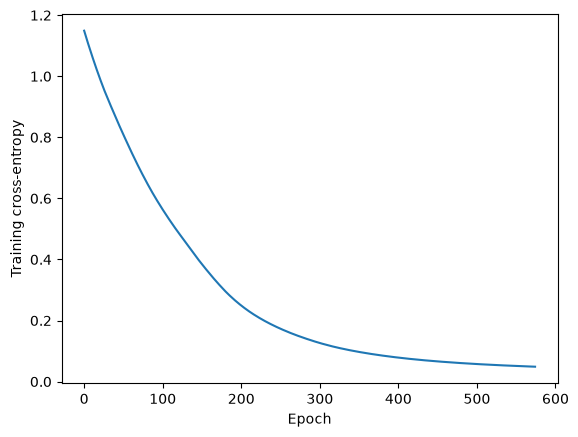

In [4]:
base=MLPClassifier(hidden_layer_sizes=(10,10),learning_rate_init=.001,max_iter=1000,random_state=SEED)
base.fit(Xtr,ytr)
print('Layers:',base.n_layers_,'iterations:',base.n_iter_,'output:',base.out_activation_)
print('Weight shapes:',[w.shape for w in base.coefs_])
print('Parameters:',sum(w.size for w in base.coefs_)+sum(b.size for b in base.intercepts_))
plt.plot(base.loss_curve_);plt.xlabel('Epoch');plt.ylabel('Training cross-entropy');plt.show()

## Step 4 — Complete the architecture and learning-rate experiments
Change one factor at a time by reading across the table. Convergence warnings mean the iteration budget was reached, not that a better model was found. More neurons need not generalize better.

C:\Users\Muhammad Naveed\AppData\Roaming\Python\Python314\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\Muhammad Naveed\AppData\Roaming\Python\Python314\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


C:\Users\Muhammad Naveed\AppData\Roaming\Python\Python314\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


C:\Users\Muhammad Naveed\AppData\Roaming\Python\Python314\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


,model,train_accuracy,val_accuracy,epochs
1,"(5,) lr=0.001",0.988889,0.966667,1000
8,"(32, 16) lr=0.01",0.977778,0.933333,80
5,"(10, 10) lr=0.01",1.000000,0.933333,279
2,"(5,) lr=0.01",0.977778,0.933333,309
4,"(10, 10) lr=0.001",0.977778,0.933333,575
7,"(32, 16) lr=0.001",0.977778,0.900000,380
6,"(32, 16) lr=0.0001",0.977778,0.900000,1000
3,"(10, 10) lr=0.0001",0.722222,0.766667,1000
0,"(5,) lr=0.0001",0.744444,0.633333,1000


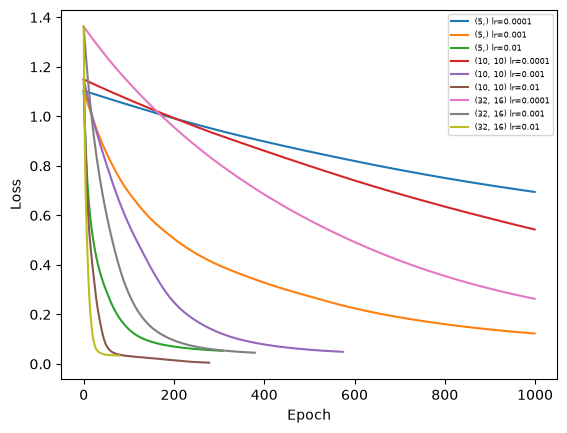

Selected using validation: (5,) lr=0.001
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      0.90      0.95        10
           2       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



WindowsPath('D:/Disk E/Robotics And Ai/Deep  Learning/completed-tutorials/artifacts/02_mlp.json')

In [5]:
rows=[]; models={}
for layers in [(5,),(10,10),(32,16)]:
    for lr in [.0001,.001,.01]:
        m=MLPClassifier(hidden_layer_sizes=layers,learning_rate_init=lr,max_iter=1000,random_state=SEED).fit(Xtr,ytr)
        key=str(layers)+' lr='+str(lr);models[key]=m
        rows.append({'model':key,'train_accuracy':m.score(Xtr,ytr),'val_accuracy':m.score(Xv,yv),'epochs':m.n_iter_})
results=pd.DataFrame(rows).sort_values(['val_accuracy','epochs'],ascending=[False,True]); display(results)
for key,m in models.items():plt.plot(m.loss_curve_,label=key)
plt.xlabel('Epoch');plt.ylabel('Loss');plt.legend(fontsize=6);plt.show()
best=models[results.iloc[0]['model']]
print('Selected using validation:',results.iloc[0]['model'])
print(classification_report(yte,best.predict(Xte)))
save_result('02_mlp',{'validation_comparison':rows,'selected_test_accuracy':best.score(Xte,yte)})

## Step 5 — Forward and backward pass by hand
For sigmoid plus binary cross-entropy, the output error is p−y. Hidden error multiplies the output weight by sigmoid derivative. Compute every gradient with the OLD weights, then update. The finite-difference check verifies a weight gradient.

In [6]:
def sig(z):return 1/(1+np.exp(-z))
x=np.array([.5,.8]); y=1.
W1=np.array([[.1,.2],[.3,.4]]); b1=np.array([.1,.1]); W2=np.array([.3,.5]); b2=.1
h=sig(W1@x+b1); p=sig(W2@h+b2); loss=-np.log(p)
d2=p-y; d1=W2*d2*h*(1-h)
gW2=d2*h; gW1=np.outer(d1,x)
eps=1e-5
Wp=W1.copy(); Wm=W1.copy(); Wp[0,0]+=eps;Wm[0,0]-=eps
f=lambda W:-np.log(sig(W2@sig(W@x+b1)+b2))
numeric=(f(Wp)-f(Wm))/(2*eps)
print('Hidden:',h,'p:',p,'loss:',loss,'output delta:',d2)
print('dW1:',gW1,'dW2:',gW2,'db1:',d1,'db2:',d2)
assert np.isclose(numeric,gW1[0,0],atol=1e-7)
W1-=.1*gW1;b1-=.1*d1;W2-=.1*gW2;b2-=.1*d2
print('After one update:',-np.log(sig(W2@sig(W1@x+b1)+b2)))

Hidden: [0.57688526 0.63876318] p: 0.6439264419848797 loss: 0.44017077992181697 output delta: -0.3560735580151203
dW1: [[-0.01303703 -0.02085924]
 [-0.02054053 -0.03286485]] dW2: [-0.20541359 -0.22744668] db1: [-0.02607405 -0.04108106] db2: -0.3560735580151203
After one update: 0.4180855255578507


## Explain it in class
Describe the input, target, model, loss, update rule and evaluation split. Use the displayed results from your own run. Changing the dataset, seed or training budget can change the result.

**Course source:** the matching tutorial PDF supplied in the Deep Learning course. Original explanatory implementation; the course PDFs are not redistributed.

## Task answers and revision check

**Which configuration performed best here?** In the recorded run, one hidden layer of 5 neurons with learning rate 0.001 achieved the highest validation accuracy, 96.67%. It also achieved 96.67% on the held-out 30-example test set. A difference of one test example is 3.33 percentage points, so do not overinterpret small differences.

**Did a larger network always help?** No. The (32,16) alternatives did not beat the selected small model on this validation split. Capacity alone does not determine generalization.

**What did the learning rate change?** The very small 0.0001 rate left some small models undertrained within 1,000 epochs. A 0.01 rate often reached the stopping criterion faster. Fast convergence and the highest validation accuracy are different objectives.

**Why is the gradient not always (correct−output)×input?** That expression is a particular update convention. Backpropagation differentiates the chosen loss and activation. For sigmoid+BCE, the loss gradient is (p−y)x; gradient descent subtracts it.

**Numerical check:** with probability 0.7 for the true class, CE = −ln(0.7) ≈ 0.357. Macro averaging weights classes equally; support-weighted averaging weights by actual class counts.
